# DGSA — supplementary figures

DGSA settings: chem-only = 250 draws, 4 clusters; full = 3000 runs (250 geochem x 12 schedules), 6 clusters; 3000 bootstraps.

Error bars are pyDGSA's confidence width drawn as ± half-width. A bar is "significant" when its lower bound clears 1.

In [7]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform

from pyDGSA.cluster import KMedoids
from pyDGSA.dgsa import dgsa

SIG, NOT_SIG = "C0", "lightgray"
STAGE_COLOR = {"dissolution": "C0", "export": "C1"}

# display names for parameters in the figures -- fill in
PARAM_LABEL = {
    "apprate_base":      "Application flux",
    "cec_factor":        "CEC factor",
    "log10_dustrad":     "Grain size",
    "log10_qrun_factor": "Infiltration factor",
    "log10_C0_over_L":   "C0/L",
    "k":                 "k",
    "log10_L":           "L",
}

EXP_GROUP  = "gcam_dgsa_v1.2"
EXP_SET    = "exe_central1p5"
SAVE_GROUP = "gcam"
idx        = "001"
SCURVE_SET = "synthetic-dgsa-v1.2"
S3         = "s3://carbonplan-carbon-removal/ew-workflows-data"
chempath   = f"{S3}/scepter/postprocessed/{SAVE_GROUP}/{EXP_GROUP}/{EXP_SET}_{idx}"
allpath    = f"{chempath}_multiSchedule/{SCURVE_SET}"
fn_sum     = "ds_cdr_globalScaling_constApp_SUM.zarr"

SAVE_ON  = True
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
savehere = REPO / "figures/supp/panels"
savehere.mkdir(parents=True, exist_ok=True)

N_CLUSTERS = {"chem": 4, "all": 6}
N_BOOTS    = 3000
SEED       = 42

RESP_LABEL = {
    "cdr_total":   "Cumulative CDR",
    "cdr_eff_int": "CDR efficiency",
    "diss_frac_int": "Dissolution fraction",
    "adv_eff_int":   "Alkalinity export fraction",
    "lag_app_cdr": "CDR lag",
}


def build_responses(ds, row_dim):
    """Cumulative CDR as a log10 trajectory (time 1-79); the rest are single 80-yr / P50 columns."""
    cdr  = ds["cdr_adv_globe"].compute()
    pot  = ds["gcam_cdr_globe"].compute()
    gbas = ds["catbudget_gbas_region"].sum("site").compute()
    diss = ds["total_dissolution_region"].sum("site").compute()    # already cumulative
    app  = ds["int_dust_ton_ha_yr_region"].sum("site").compute()   # already cumulative

    def curve(da):
        v = da.isel(time=slice(1, None)).transpose(row_dim, "time").values
        assert (v > 0).all()
        return np.log10(v)

    ratio = lambda n, d: curve(n / d.where(d > 0))
    cdr_eff = ratio(cdr.cumsum("time"), pot.cumsum("time"))
    lag = ds["global_curve_summed"].sel(metric="t_app_cdr_adv_global_P50").compute()
    return {"cdr_total":   curve(cdr.cumsum("time")),
            "cdr_eff_int": cdr_eff[:, -1:],
            "diss_frac_int": ratio(diss, app)[:, -1:],
            "adv_eff_int": ratio(cdr.cumsum("time"), gbas.cumsum("time"))[:, -1:],
            "lag_app_cdr": lag.transpose(row_dim).values[:, None]}


def main_effects(X, names, responses, n_clusters):
    """Sensitivity, CI half-width and lower bound per response (seeded per response)."""
    out = {}
    for k, data in responses.items():
        d = squareform(pdist(data, metric="euclidean"))
        labels, _ = KMedoids(n_clusters=n_clusters, max_iter=3000, tol=1e-4,
                             random_state=SEED).fit_predict(d)
        np.random.seed(SEED)
        s = dgsa(X, labels, parameter_names=names, confidence=True, n_boots=N_BOOTS, progress=False)
        out[k] = pd.DataFrame({"sens": s["sensitivity"], "half": s["confidence"] / 2})
        out[k]["lower"] = out[k]["sens"] - out[k]["half"]
    return out


def ranked_panel(ax, df, title):
    df = df.sort_values("sens")
    y = np.arange(len(df))
    sig = (df["lower"] > 1).values
    ax.barh(y, df["sens"], xerr=df["half"], color=np.where(sig, SIG, NOT_SIG), capsize=3)
    ax.set_yticks(y, [PARAM_LABEL.get(p, p) for p in df.index])
    ax.axvline(1, color="gray", ls="--")
    ax.set_xlim(0, (df["sens"] + df["half"]).max() * 1.1)
    ax.set(xlabel="DGSA sensitivity", title=title)


def legend_panel(ax, note):
    ax.axis("off")
    ax.legend([plt.Rectangle((0, 0), 1, 1, fc=SIG), plt.Rectangle((0, 0), 1, 1, fc=NOT_SIG),
               plt.Line2D([], [], color="gray", ls="--")],
              ["significantly > 1 (lower bound > 1)", "not significant", "sensitivity = 1"],
              loc="upper left")
    ax.text(0.0, 0.45, note, transform=ax.transAxes, va="top")

In [8]:
# --- chem-only (fixed GCAM schedule)
dsc = xr.open_zarr(os.path.join(chempath, fn_sum))
CHEM_PARAMS = ["apprate_base", "cec_factor", "log10_dustrad", "log10_qrun_factor"]
Xc = np.column_stack([dsc["apprate_base"].isel(site=0).values, dsc["cec_factor"].isel(site=0).values,
                      np.log10(dsc["dustrad"].isel(site=0).values),
                      np.log10(dsc["qrun_factor"].isel(site=0).values)])
RC = build_responses(dsc, "collapsed_inputs")
del RC["cdr_total"]   # fixed schedule: clusters exactly like the CDR-efficiency trajectory
SENS_C = main_effects(Xc, CHEM_PARAMS, RC, N_CLUSTERS["chem"])

# --- full (chem + deployment)
dsa = xr.open_zarr(os.path.join(allpath, fn_sum))
GROUPS = {"deployment": ["log10_C0_over_L", "k", "log10_L"], "intensity": ["apprate_base"],
          "geochem": ["cec_factor", "log10_dustrad", "log10_qrun_factor"]}
ALL_PARAMS = [p for g in GROUPS.values() for p in g]
pa = pd.DataFrame({
    "log10_C0_over_L":   dsa["log10_C0_over_L"].values,
    "k":                 dsa["k"].values,
    "log10_L":           dsa["log10_L"].values,
    "apprate_base":      dsa["apprate_base"].values,
    "cec_factor":        dsa["cec_factor"].values,
    "log10_dustrad":     np.log10(dsa["dustrad"].values),
    "log10_qrun_factor": np.log10(dsa["qrun_factor"].values),
})
RA = build_responses(dsa, "schedule_name")
SENS_A = main_effects(pa.values, ALL_PARAMS, RA, N_CLUSTERS["all"])

# --- per-geochem-draw delay penalty: slope of log10 80-yr efficiency on t_bar across 12 schedules
t = dsa["time"].values
target = dsa["gcam_cdr_globe"].compute().transpose("schedule_name", "time").values
cum = lambda v: dsa[v].sum("site").compute().cumsum("time").isel(time=-1).values
cdr80 = dsa["cdr_adv_globe"].compute().sum("time").values
d = pd.DataFrame({
    "geo":   dsa["lhs_sample_id"].values,
    "t_bar": (target * t).sum(1) / target.sum(1),       # demand-weighted mean application year
    "leff":  np.log10(cdr80 / target.sum(1)),
    "ldiss": np.log10((dsa["total_dissolution_region"].sum("site")
                       / dsa["int_dust_ton_ha_yr_region"].sum("site")).isel(time=-1).values),
    "ladv":  np.log10(cdr80 / cum("catbudget_gbas_region")),
    "log10_dustrad": pa["log10_dustrad"],
})
pen = lambda s: 1 - 10 ** (10 * s)                       # fractional loss per decade of t_bar
per = d.groupby("geo").agg(log10_dustrad=("log10_dustrad", "first"))
for c, name in [("leff", "pen"), ("ldiss", "pen_diss"), ("ladv", "pen_adv")]:
    per[name] = pen(pd.Series({g: np.polyfit(s["t_bar"], s[c], 1)[0] for g, s in d.groupby("geo")}))
print(f"delay penalty per decade: median {per.pen.median():.2f}")

delay penalty per decade: median 0.54


## 1. Ranked sensitivities — chemistry only (fixed GCAM schedule, n = 250)

Hold the GCAM target rock application constant for every draw and vary only the geochemistry.
Cumulative CDR is left out: potential CDR is the same for every draw here, so cumulative CDR
clusters exactly like the CDR-efficiency trajectory.

In [9]:
RESP_LABEL

{'cdr_total': 'Cumulative CDR',
 'cdr_eff_int': 'CDR efficiency',
 'diss_frac_int': 'Dissolution fraction',
 'adv_eff_int': 'Alkalinity export fraction',
 'lag_app_cdr': 'CDR lag'}

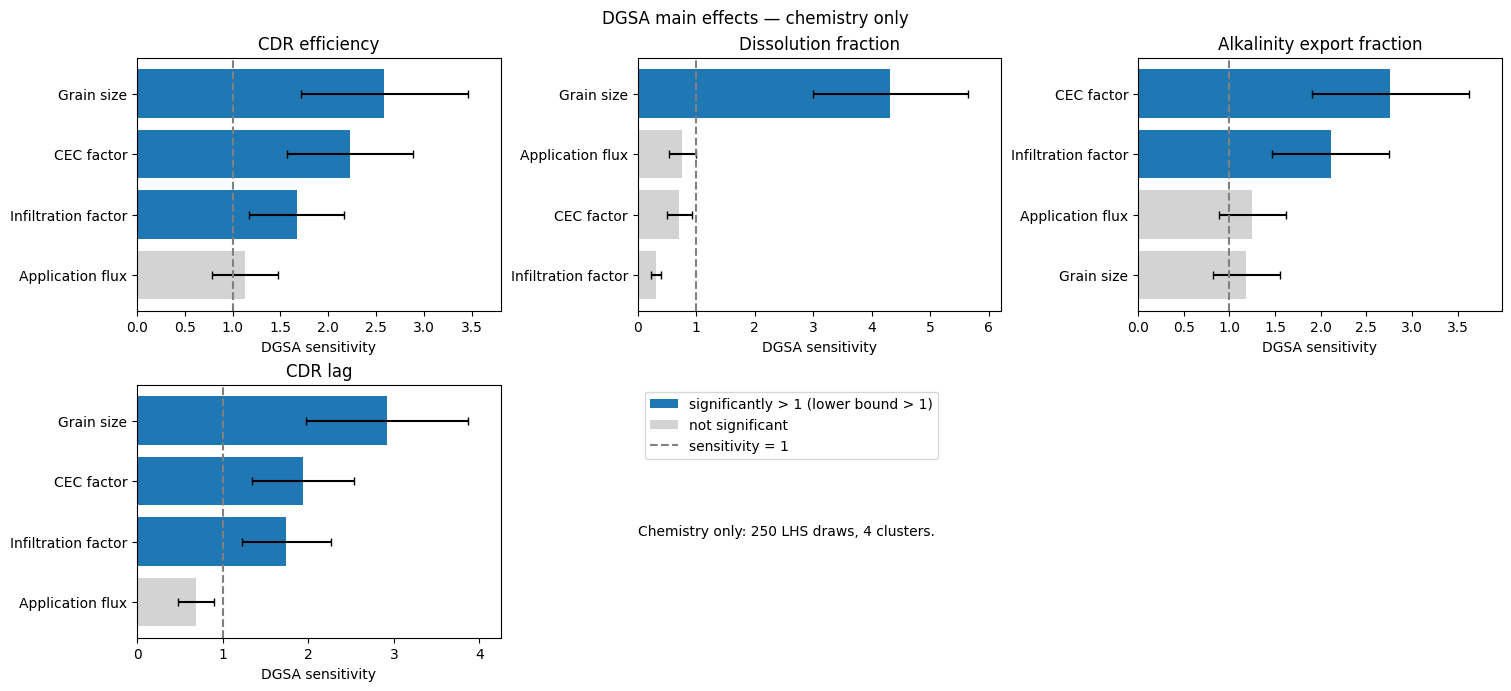

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6.8), layout="constrained")
axes = axes.ravel()
for ax, (k, df) in zip(axes, SENS_C.items()):
    ranked_panel(ax, df, RESP_LABEL[k])
legend_panel(axes[len(SENS_C)], "Chemistry only: 250 LHS draws, 4 clusters.")
for ax in axes[len(SENS_C) + 1:]:
    ax.axis("off")
fig.suptitle("DGSA main effects — chemistry only")
if SAVE_ON:
    fig.savefig(os.path.join(savehere, "dgsa-mainEffects-chemOnly.png"), dpi=300, bbox_inches="tight")
plt.show()

## 2. Ranked sensitivities — chemistry + deployment (n = 3000)

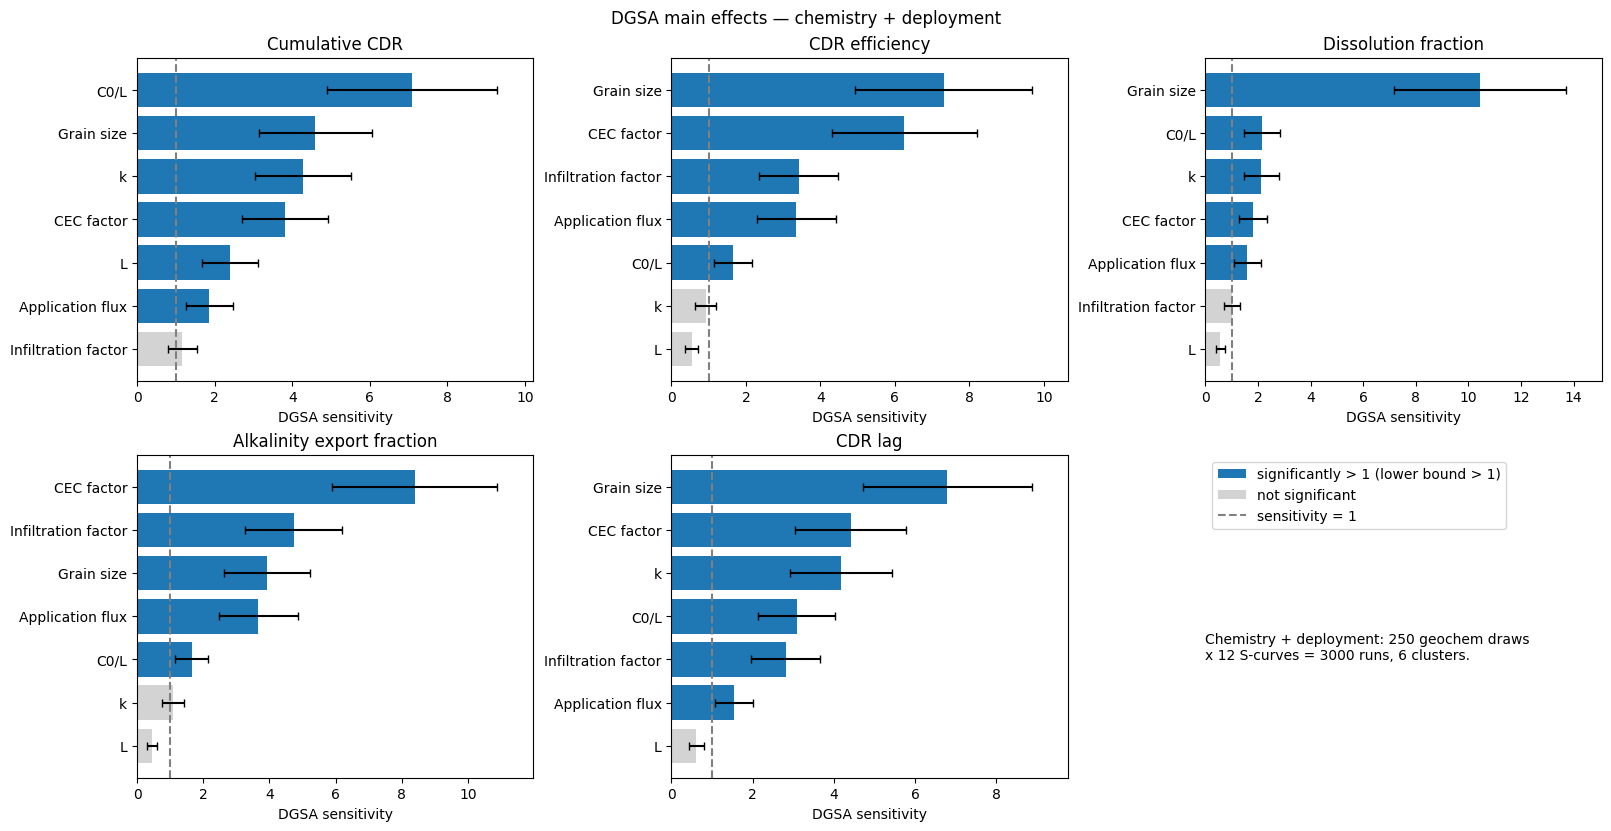

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.2), layout="constrained")
for ax, (k, df) in zip(axes.flat, SENS_A.items()):
    ranked_panel(ax, df, RESP_LABEL[k])
legend_panel(axes.flat[-1], "Chemistry + deployment: 250 geochem draws\n"
             "x 12 S-curves = 3000 runs, 6 clusters.\n")
fig.suptitle("DGSA main effects — chemistry + deployment")
if SAVE_ON:
    fig.savefig(os.path.join(savehere, "dgsa-mainEffects-full.png"), dpi=300, bbox_inches="tight")
plt.show()

## 3. CDR efficiency across sampled geochemistry (chemistry only)

0.38 is the manuscript's land-limited, GCAM-matched SCEPTER efficiency. 0.10 is the threshold the
manuscript uses for likely overcoming upstream emissions.

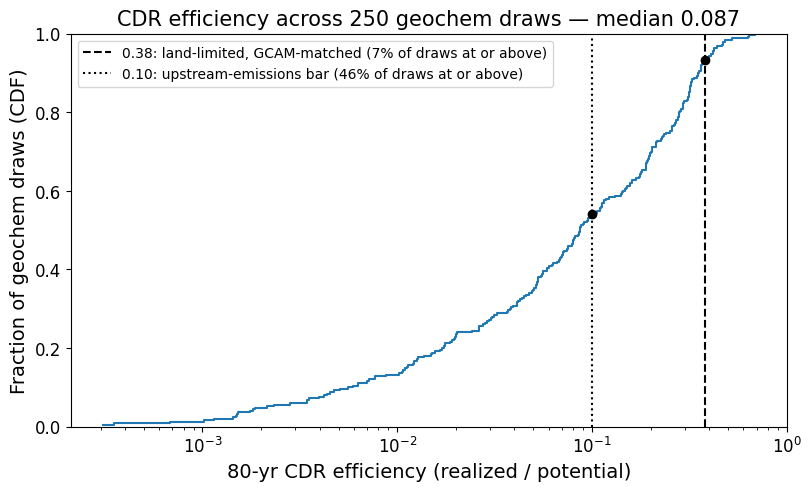

In [12]:
eff = 10 ** RC["cdr_eff_int"][:, 0]
xs = np.sort(eff)
fig, ax = plt.subplots(figsize=(8, 4.8), layout="constrained")
ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post")
for th, lab, ls in [(0.38, "land-limited, GCAM-matched", "--"), (0.10, "upstream-emissions bar", ":")]:
    ax.axvline(th, color="k", ls=ls,
               label=f"{th:.2f}: {lab} ({100 * np.mean(eff >= th):.0f}% of draws at or above)")
    ax.plot(th, np.mean(eff < th), "ko")
ax.legend(loc="upper left")
ax.set(xscale="log", ylim=(0, 1))
ax.set_xlabel("80-yr CDR efficiency (realized / potential)", fontsize=14)
ax.set_ylabel("Fraction of geochem draws (CDF)", fontsize=14)
ax.tick_params(which="both", labelsize=12)
ax.set_title(f"CDR efficiency across {len(eff)} geochem draws — median {np.median(eff):.3f}",
             fontsize=15)
if SAVE_ON:
    fig.savefig(os.path.join(savehere, "dgsa-cdrEff-cdf.png"), dpi=300, bbox_inches="tight")
plt.show()

## 4. Delay penalty by grain size

For each geochem draw, the per-decade loss is the slope of log10 80-yr CDR efficiency against
`t_bar` (demand-weighted mean application year) across that draw's 12 schedules. It is split into a
dissolution part and an export/retention part. Bars and diamonds are medians within each
`log10_dustrad` quartile.

Strictly, "delay" in adoption here means a delay in the temporal centroid of rock application.

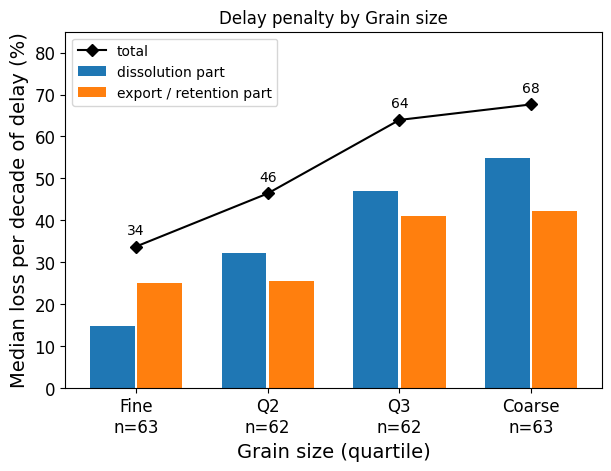

In [13]:
bins = pd.qcut(per["log10_dustrad"], 4, labels=["Fine", "Q2", "Q3", "Coarse"])
g = per.groupby(bins, observed=True)
med = g[["pen", "pen_diss", "pen_adv"]].median()
x = np.arange(len(med))

fig, ax = plt.subplots(figsize=(6, 4.6), layout="constrained")
ax.bar(x - 0.18, 100 * med.pen_diss, width=0.34, color=STAGE_COLOR["dissolution"],
       label="dissolution part")
ax.bar(x + 0.18, 100 * med.pen_adv, width=0.34, color=STAGE_COLOR["export"],
       label="export / retention part")
ax.plot(x, 100 * med.pen, "kD-", label="total")
for i, v in enumerate(med.pen):
    ax.text(i, 100 * v + 3, f"{100 * v:.0f}", ha="center")
ax.set_xticks(x, [f"{c}\nn={n}" for c, n in zip(med.index, g.size())])
ax.set_ylim(0, 85)
ax.set_xlabel(f"{PARAM_LABEL['log10_dustrad']} (quartile)", fontsize=14)
ax.set_ylabel("Median loss per decade of delay (%)", fontsize=14)
ax.tick_params(labelsize=12)
ax.set_title(f"Delay penalty by {PARAM_LABEL['log10_dustrad']}")
ax.legend(loc="upper left")
if SAVE_ON:
    fig.savefig(os.path.join(savehere, "dgsa-delayPenalty-grainSize.png"), dpi=300, bbox_inches="tight")
plt.show()

In [14]:
rng = (10 ** per["log10_dustrad"]).groupby(bins, observed=True).agg(["min", "max"])
for c, r in rng.iterrows():
    print(f"{c:>6}: {r['min']:.3g} – {r['max']:.3g}")

  Fine: 0.334 – 0.976
    Q2: 0.998 – 2.84
    Q3: 2.93 – 8.35
Coarse: 8.45 – 25


In [ ]:
# ---